# Cats vs Dogs Image Classification

## Project Overview
In this project, we build a Convolutional Neural Network (CNN) to classify images into two categories: cats and dogs.

## Objectives
- Load and explore the Cats vs Dogs dataset.
- Preprocess images for model training.
- Build and train a CNN model using TensorFlow and Keras.
- Evaluate the model's performance on test data.

## Tools and Libraries
- Python
- TensorFlow and Keras
- TensorFlow Datasets (TFDS)
- NumPy
- Matplotlib

## Dataset
The dataset contains images of cats and dogs. Each image is associated with a label indicating its class.

## Workflow
1. Load the dataset.
2. Explore the images and labels.
3. Preprocess the images.
4. Split the data into training and testing sets.
5. Build and train the CNN model.
6. Evaluate the model.

In [5]:
!pip install -q importlib-resources

In [6]:
import tensorflow as tf
from tensorflow import keras
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

## 1. Load the Dataset

We use TensorFlow Datasets (TFDS) to load the Cats vs Dogs dataset.

By setting `as_supervised=True`, each sample is returned as a tuple containing an image and its corresponding label.

In [7]:
catdog = tfds.load(
    "cats_vs_dogs",
    split="train",
    as_supervised=True
)

train = catdog.take(800)
test = catdog.skip(800).take(200)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.FQS449_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.


## 2. Inspect the Dataset

We inspect one sample to understand the image dimensions and the format of its label.

In [8]:
for image, label in catdog.take(1):
    print("Image shape:", image.shape)
    print("Label shape:", label.shape)
    print("Label value:", label.numpy())

Image shape: (262, 350, 3)
Label shape: ()
Label value: 1


In [9]:
print("Train size:", train.cardinality().numpy())
print("Test size:", test.cardinality().numpy())

Train size: 800
Test size: 200


## 3. Visualize Sample Images

We display a few images from the training dataset along with their labels to better understand the data.

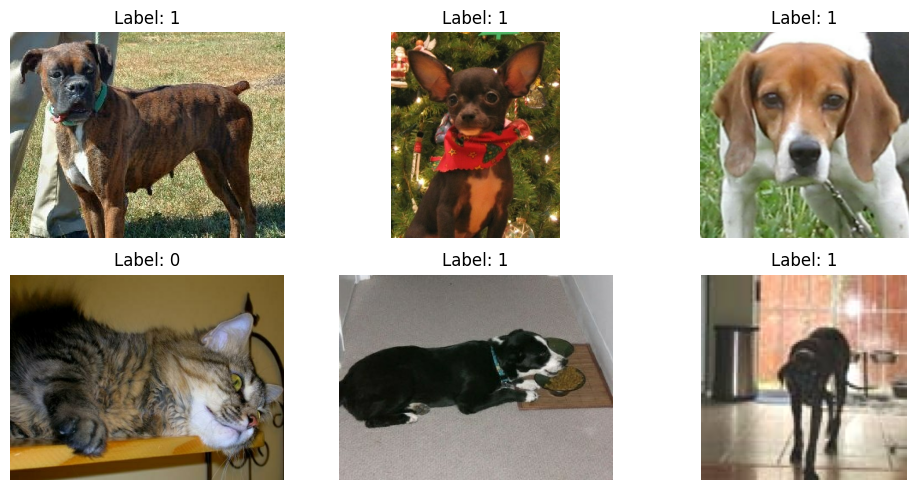

In [10]:
plt.figure(figsize=(10, 5))

for i, (image, label) in enumerate(train.take(6)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(image.numpy())
    plt.title(f"Label: {label.numpy()}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 4. Image Preprocessing

Before training the CNN, we resize all images to a fixed size and normalize their pixel values to the range [0, 1]. This helps prepare the images for model training.

In [11]:

def preprocess_image(image, label):
    image = tf.image.resize(image, (128, 128))
    image = image / 255.0
    return image, label

In [12]:
train = train.map(preprocess_image)
test = test.map(preprocess_image)

In [13]:
for image, label in train.take(1):
    print("Image shape:", image.shape)
    print("Image dtype:", image.dtype)
    print("Minimum pixel value:", tf.reduce_min(image).numpy())
    print("Maximum pixel value:", tf.reduce_max(image).numpy())
    print("Label:", label.numpy())

Image shape: (128, 128, 3)
Image dtype: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Label: 1


## 5. Prepare Data for Training

We batch the training and testing datasets to process multiple images at a time during model training and evaluation.

In [14]:
BATCH_SIZE = 32

train = train.shuffle(800).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test = test.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

## 6. Build the CNN Model

We build a Convolutional Neural Network (CNN) to extract visual features from images and classify them into two categories: cats and dogs.

The model consists of convolutional layers, max-pooling layers, a flattening layer, and dense layers.

In [15]:
model = keras.Sequential([
    keras.layers.Input(shape=(128, 128, 3)),

    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

## 7. Compile the Model

We compile the model using the Adam optimizer and binary cross-entropy loss, which are suitable for binary image classification.

We use accuracy to measure the proportion of correctly classified images.

In [16]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

## 8. Train the Model

We train the CNN model using the training dataset for multiple epochs. During training, the model learns visual patterns that help distinguish cats from dogs.

## 8. Train the Model

We train the CNN model using the training dataset for 10 epochs. During training, the model learns visual patterns that help distinguish cats from dogs.

In [17]:
history = model.fit(
    train,
    epochs=10
)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 28s 967ms/step - accuracy: 0.5013 - loss: 1.0301
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 22s 847ms/step - accuracy: 0.5825 - loss: 0.6771
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 24s 922ms/step - accuracy: 0.6500 - loss: 0.6571
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 40s 861ms/step - accuracy: 0.6925 - loss: 0.5578
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 41s 860ms/step - accuracy: 0.8050 - loss: 0.4447
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 25s 946ms/step - accuracy: 0.8462 - loss: 0.3308
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 40s 915ms/step - accuracy: 0.9287 - loss: 0.1973
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 41s 870ms/step - accuracy: 0.9563 - loss: 0.1374
Epoch 9/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 23s 885ms/step - accuracy: 0.9850 - loss: 0.0650
Epoch 10/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 23s 862ms/step - accuracy: 0.9962 - loss: 0.0357


## 9. Visualize Training Performance

We plot the training accuracy and loss across epochs to observe how the model learns over time.

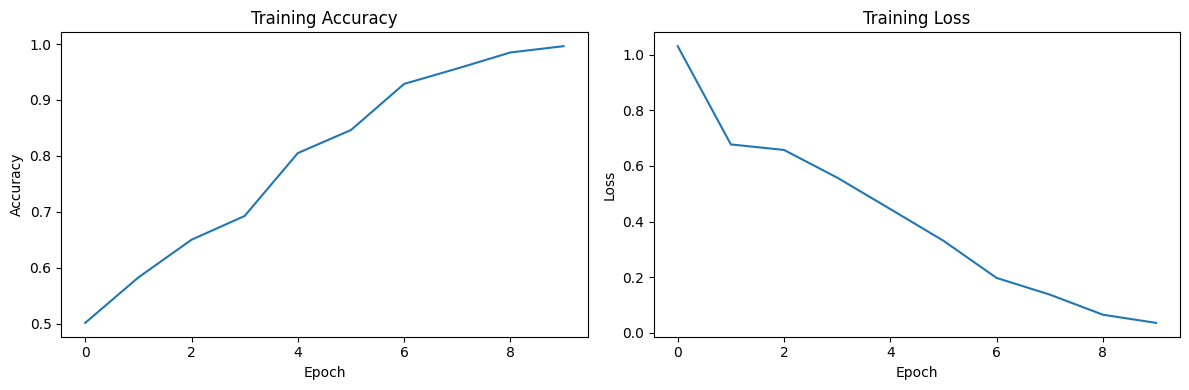

In [18]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"])
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"])
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()

## 10. Evaluate the Model

We evaluate the trained CNN on the test dataset to measure its performance on unseen images.

In [19]:
test_loss, test_accuracy = model.evaluate(test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 212ms/step - accuracy: 0.6450 - loss: 1.3561
Test Loss: 1.3561040163040161
Test Accuracy: 0.6449999809265137


## 11. Results

The CNN model achieved a test accuracy of approximately 64.5% and a test loss of 1.36.

These results provide a baseline for binary image classification. Further improvements could include data augmentation, model architecture optimization, and hyperparameter tuning.